# Understanding the Bias-Variance Tradeoff in Value Estimation

## Introduction

Monte Carlo and temporal-difference learning solve the same prediction problem. Given a policy, we want to estimate the expected return from each state. The difference is in the target used to update those estimates.

Monte Carlo uses the complete sampled return. TD(0) uses one sampled reward and the estimated value of the next state. This is usually described as a bias-variance tradeoff: Monte Carlo avoids bootstrap bias, but its targets can have more variance. TD replaces part of the sampled return with an estimate, which can reduce variance at the cost of bias.

In this post, we'll examine that tradeoff in two stages. First, we'll use independent rewards in a one-state environment to isolate the mechanism. Then we'll move to a two-state environment with a fixed policy and state-dependent rewards. We'll let the methods learn and compare their estimates across independent training runs.

## Monte Carlo and TD Targets

For a fixed policy $\pi$, the state-value function is the expected return:

$$v_\pi(s)=\mathbb{E}_\pi[G_t\mid S_t=s].$$

For an episode ending at time $T$, the Monte Carlo target is:

$$Y_{\mathrm{MC}}=G_t=\sum_{k=0}^{T-t-1}\gamma^kR_{t+k+1}.$$

TD(0) instead uses:

$$Y_{\mathrm{TD}}=R_{t+1}+\gamma\hat V(S_{t+1}).$$

For a terminal transition, the TD target is just the reward. Both methods move the current estimate toward the target:

$$\hat V(S_t)\leftarrow\hat V(S_t)+\alpha\left[Y-\hat V(S_t)\right].$$

The target is the quantity we move toward. It is different from both the current value estimate and the error, $Y-\hat V(S_t)$.

## Measuring Bias and Variance

For a random estimate $X$ of a true quantity $v$, bias measures the difference between the estimate's expected value and the truth:

$$\operatorname{Bias}(X)=\mathbb{E}[X]-v.$$

Bias is signed. An estimate that is too high has positive bias. Variance measures the spread around the estimate's own mean:

$$\operatorname{Var}(X)=\mathbb{E}\left[(X-\mathbb{E}[X])^2\right].$$

Mean squared error combines them:

$$\operatorname{MSE}(X)=\operatorname{Bias}(X)^2+\operatorname{Var}(X).$$

An RMSE curve alone doesn't show how much error comes from bias and how much comes from variance. We'll measure the components separately.

There are two different quantities we can examine. We can collect many update targets while keeping the bootstrap values fixed. Alternatively, we can repeat the entire training process and collect the learned values after the same amount of training. We'll start with the targets, then move to the learned estimates.

### Setup and Imports

First, we import the libraries and define the experiment settings. NumPy is sufficient for these small tabular examples. The notebook needs `numpy`, `pandas`, `matplotlib`, and `ipython`; it does not depend on a separate environment package or the earlier experiment scripts.

In [1]:
from dataclasses import dataclass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython import get_ipython
from IPython.display import display

# Display Matplotlib figures directly in the notebook.
ipython = get_ipython()
if ipython is not None:
    ipython.run_line_magic("matplotlib", "inline")


@dataclass
class Config:
    runs: int = 500
    episodes: int = 1000
    target_samples: int = 100_000
    alpha: float = 0.05
    gamma: float = 0.9
    horizon: int = 20
    seed: int = 42


config = Config()

# Record the early episodes and a few later training budgets.
early_episodes = np.arange(1, 11)
later_episodes = np.geomspace(1, config.episodes, 80).astype(int)
training_budgets = np.array([10, 30, 100, 300, config.episodes])

checkpoints = np.concatenate((early_episodes, later_episodes, training_budgets))
checkpoints = np.unique(checkpoints)

plt.rcParams.update({
    "figure.dpi": 120,
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.figsize": (9, 4),
})

COLORS = {
    "TD(0)": "#ce7025",
    "MC": "#2673b8",
}

display(pd.DataFrame([vars(config)]))

,runs,episodes,target_samples,alpha,gamma,horizon,seed
0,500,1000,100000,0.05,0.9,20,42


### Computing the Statistics

The following function computes empirical bias, variance, and MSE across repetitions. A small nonzero measured bias can be sampling error, so we distinguish these measurements from the exact bias where it is available.

We use `ddof=0` so the decomposition holds exactly for the empirical distribution. The comparison table keeps each method's statistics in a separate row.

In [2]:
def prediction_statistics(samples, truth, axis=-1):
    # Average across repetitions, keeping the training checkpoint fixed.
    mean = np.mean(samples, axis=axis)
    bias = mean - truth

    # Variance is measured around the sample mean, rather than the truth.
    variance = np.var(samples, axis=axis, ddof=0)
    squared_errors = (samples - truth) ** 2
    mse = np.mean(squared_errors, axis=axis)

    np.testing.assert_allclose(mse, bias**2 + variance, atol=1e-10)

    statistics = {
        "mean": mean,
        "bias": bias,
        "bias_squared": bias**2,
        "variance": variance,
        "mse": mse,
    }
    return statistics


def comparison_table(samples, truth):
    # Collect the statistics for each method in a separate table row.
    results = {}

    for method, values in samples.items():
        results[method] = prediction_statistics(values, truth)

    table = pd.DataFrame(results).T
    table.index.name = "Method"
    return table

In [3]:
def plot_learning_curves(samples, times, truth, title):
    fig, axes = plt.subplots(2, 2, figsize=(11, 7))
    statistic_names = ("mean", "bias_squared", "variance", "mse")

    for method, values in samples.items():
        statistics = prediction_statistics(values, truth)
        color = COLORS[method]

        for ax, name in zip(axes.flat, statistic_names):
            ax.plot(times, statistics[name], label=method, color=color)

        mean = statistics["mean"]
        standard_deviation = np.sqrt(statistics["variance"])
        axes[0, 0].fill_between(
            times,
            mean - standard_deviation,
            mean + standard_deviation,
            color=color,
            alpha=0.12,
        )

    axes[0, 0].axhline(
        truth, color="black", linestyle="--", label=f"Truth: {truth:.3f}"
    )

    titles = (
        "Mean learned value (+/- 1 SD)",
        "Squared bias",
        "Variance across runs",
        "MSE",
    )

    for ax, panel_title in zip(axes.flat, titles):
        ax.set_title(panel_title)
        ax.set_xlabel("Training episodes per run")
        ax.set_xscale("log")
        ax.grid(alpha=0.15)
        ax.legend(frameon=False)

    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


def plot_learned_distributions(samples, times, truth, title):
    training_budgets = [10, 100, 1000]
    checkpoint_indices = []

    for budget in training_budgets:
        index = np.flatnonzero(times == budget)[0]
        checkpoint_indices.append(index)

    # Use the same bins in every panel so the spreads can be compared.
    selected_samples = []
    for values in samples.values():
        selected_samples.append(values[checkpoint_indices].ravel())

    all_values = np.concatenate(selected_samples)
    lower_bound = min(truth, all_values.min()) - 0.2
    upper_bound = max(truth, all_values.max()) + 0.2
    bins = np.linspace(lower_bound, upper_bound, 50)

    fig, axes = plt.subplots(
        len(samples), len(training_budgets),
        figsize=(13, 6), sharex=True, squeeze=False,
    )

    for row, (method, values) in enumerate(samples.items()):
        for column, budget in enumerate(training_budgets):
            index = checkpoint_indices[column]
            estimates = values[index]
            ax = axes[row, column]

            ax.hist(
                estimates,
                bins=bins,
                weights=np.ones(len(estimates)) / len(estimates),
                color=COLORS[method],
                alpha=0.8,
            )
            ax.axvline(truth, color="black", linestyle="--", label="True value")
            ax.axvline(estimates.mean(), color="#ae3150", label="Mean estimate")
            ax.set_title(f"{method}: {budget:,} episodes")
            ax.set_xlabel("Learned starting value")
            ax.set_ylabel("Fraction of runs")
            ax.legend(frameon=False, fontsize=8)

    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

## A Controlled Example: Independent Reward Noise

We'll first use one physical state, S, with one action that returns to S. At every step, the reward is sampled independently: 0 or $-2$, each with probability $1/2$. Every reward has mean $-1$ and variance 1.

There is no action-selection problem in this example. Its purpose is to isolate what happens when a return accumulates independently sampled rewards.

![One state with a deterministic transition and independently sampled rewards.](one_state_environment.png)

One state with a deterministic transition and independently sampled rewards.

### Defining the Prediction Horizon

The physical process can continue indefinitely, but we'll predict the discounted reward over exactly 20 steps, with $\gamma=0.9$. Both methods must estimate the same finite-horizon quantity.

We therefore keep track of steps remaining, $h$, and learn $V(h)$. The boundary value is $V(0)=0$. The physical state is unchanged, but a prediction with 20 steps remaining is different from a prediction with one step remaining. The diagram shows the physical transition; the horizon is part of the prediction state used by the learner.

The true value is:

$$v_h=-\sum_{k=0}^{h-1}\gamma^k.$$

We can calculate it recursively using the mean reward of $-1$.

In [4]:
def noise_exact_values(horizon, gamma):
    values = np.zeros(horizon + 1)

    for steps_remaining in range(1, horizon + 1):
        expected_reward = -1.0
        next_value = values[steps_remaining - 1]
        values[steps_remaining] = expected_reward + gamma * next_value

    return values

In [5]:
single_state_values = noise_exact_values(config.horizon, config.gamma)
single_state_truth = single_state_values[-1]

discount_weights = config.gamma ** np.arange(config.horizon)
full_return_variance = np.sum(discount_weights**2)

print(f"True 20-step value: {single_state_truth:.6f}")
print(f"Variance of one reward: {1.0:.6f}")
print(f"Variance of a full MC return: {full_return_variance:.6f}")

True 20-step value: -8.784233
Variance of one reward: 1.000000
Variance of a full MC return: 5.185364


Because the rewards are independent, the variance of the full return is:

$$\operatorname{Var}(G_0)=\sum_{k=0}^{19}\gamma^{2k}\operatorname{Var}(R_{k+1})
=\sum_{k=0}^{19}0.9^{2k}\approx5.185.$$

The episode length and state sequence are fixed. All the randomness comes from the reward draws.

### Freezing the Bootstrap Error

Now we'll freeze every nonterminal estimate two units above its true value:

$$\hat V(h)=v_h+2\quad\text{for }h>0,\qquad\hat V(0)=0.$$

An n-step target samples $n$ rewards before using the estimate for the remaining horizon:

$$Y_n=\sum_{k=0}^{n-1}\gamma^kR_{k+1}+\gamma^n\hat V(20-n).$$

For $n=1$, this is the TD(0) target. For $n=20$, it is full MC, with no bootstrap term. For $n<20$:

$$\operatorname{Bias}(Y_n)=2\gamma^n,\qquad
\operatorname{Var}(Y_n)=\sum_{k=0}^{n-1}\gamma^{2k}.$$

At $n=20$, the bias is zero. These expressions make the tradeoff explicit: longer backups discount the bootstrap error more heavily, but include more independently sampled rewards.

### Collecting the Targets

We'll collect 100,000 independent reward sequences. For each sequence, we construct every backup length from 1 to 20. Nothing learns in this experiment; the bootstrap estimates stay fixed.

In [6]:
def sample_nstep_targets(
    samples=100_000, horizon=20, gamma=0.9, error=2.0, seed=42
):
    rng = np.random.default_rng(seed)
    backup_lengths = np.arange(1, horizon + 1)
    discount_weights = gamma ** np.arange(horizon)

    true_values = noise_exact_values(horizon, gamma)
    frozen_values = true_values + error
    frozen_values[0] = 0.0  # The return beyond the horizon is exactly zero.

    rewards = -2.0 * rng.integers(2, size=(samples, horizon))
    targets = np.zeros((samples, horizon))
    sampled_returns = np.zeros(samples)
    exact_bias = np.zeros(horizon)
    exact_variance = np.zeros(horizon)

    for index, n in enumerate(backup_lengths):
        # Add one more discounted reward to the sampled part of the target.
        sampled_returns += discount_weights[index] * rewards[:, index]

        steps_remaining = horizon - n
        bootstrap_value = frozen_values[steps_remaining]
        targets[:, index] = sampled_returns + gamma**n * bootstrap_value

        if steps_remaining > 0:
            exact_bias[index] = error * gamma**n

        exact_variance[index] = np.sum(discount_weights[:n] ** 2)

    truth = true_values[-1]
    statistics = prediction_statistics(targets, truth, axis=0)
    exact_mse = exact_bias**2 + exact_variance

    # The full-horizon target must be the actual Monte Carlo return.
    np.testing.assert_allclose(targets[:, -1], rewards @ discount_weights)

    return {
        "n": backup_lengths,
        "targets": targets,
        "truth": truth,
        "mean": statistics["mean"],
        "bias": statistics["bias"],
        "variance": statistics["variance"],
        "mse": statistics["mse"],
        "theoretical_bias": exact_bias,
        "theoretical_variance": exact_variance,
        "theoretical_mse": exact_mse,
    }

In [7]:
frozen_targets = sample_nstep_targets(
    samples=config.target_samples,
    horizon=config.horizon,
    gamma=config.gamma,
    error=2.0,
    seed=config.seed,
)

target_rows = []

for n in (1, 2, 5, 20):
    index = n - 1
    row = {
        "n": n,
        "exact bias": frozen_targets["theoretical_bias"][index],
        "measured bias": frozen_targets["bias"][index],
        "exact variance": frozen_targets["theoretical_variance"][index],
        "measured variance": frozen_targets["variance"][index],
        "exact MSE": frozen_targets["theoretical_mse"][index],
    }
    target_rows.append(row)

target_table = pd.DataFrame(target_rows).set_index("n")
display(target_table.round(6))

,exact bias,measured bias,exact variance,measured variance,exact MSE
n,,,,,
1,1.80000,1.799420,1.000000,1.000000,4.240000
2,1.62000,1.618682,1.810000,1.807766,4.434400
5,1.18098,1.179095,3.428008,3.440060,4.822722
20,0.00000,-0.002220,5.185364,5.202140,5.185364


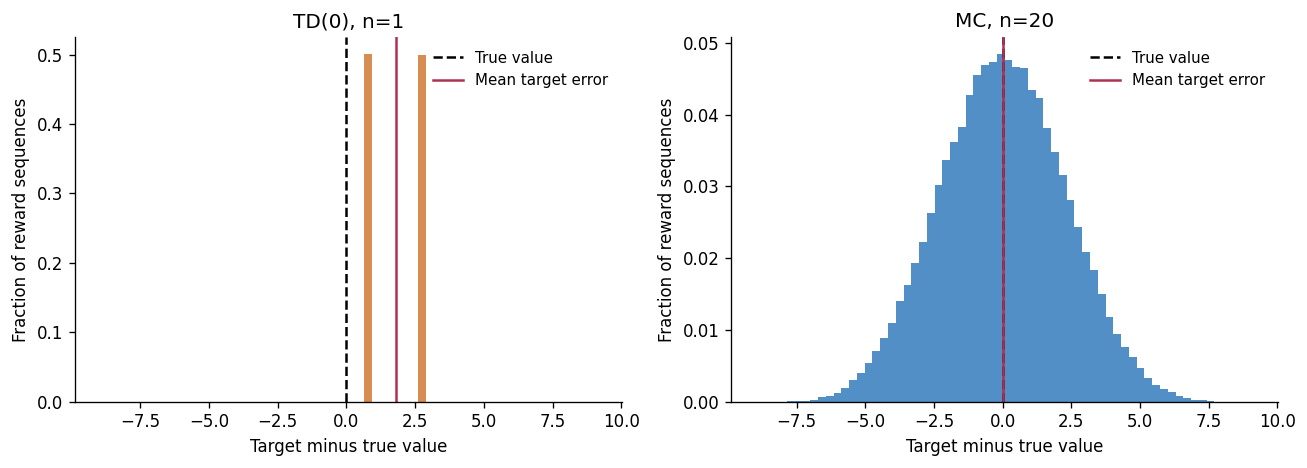

In [8]:
selected_lengths = (1, 20)
target_errors = frozen_targets["targets"] - single_state_truth
bins = np.linspace(target_errors.min() - 0.2, target_errors.max() + 0.2, 65)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, n in zip(axes, selected_lengths):
    errors = target_errors[:, n - 1]
    label = "TD(0), n=1" if n == 1 else "MC, n=20"
    color = COLORS["TD(0)"] if n == 1 else COLORS["MC"]

    ax.hist(
        errors,
        bins=bins,
        weights=np.ones(len(errors)) / len(errors),
        color=color,
        alpha=0.8,
    )
    ax.axvline(0, color="black", linestyle="--", label="True value")
    ax.axvline(errors.mean(), color="#ae3150", label="Mean target error")
    ax.set_title(label)
    ax.set_xlabel("Target minus true value")
    ax.set_ylabel("Fraction of reward sequences")
    ax.legend(frameon=False, fontsize=9)

fig.tight_layout()
plt.show()

Bias is the gap from zero; variance is the spread around the target's mean.

The one-step target has positive bias because its bootstrap value is too high. The MC target is centered on the true value but has a wider distribution. The TD target is not constant here: even with a frozen bootstrap estimate, its immediate reward is random.

We can also plot all backup lengths to see how the two components change.

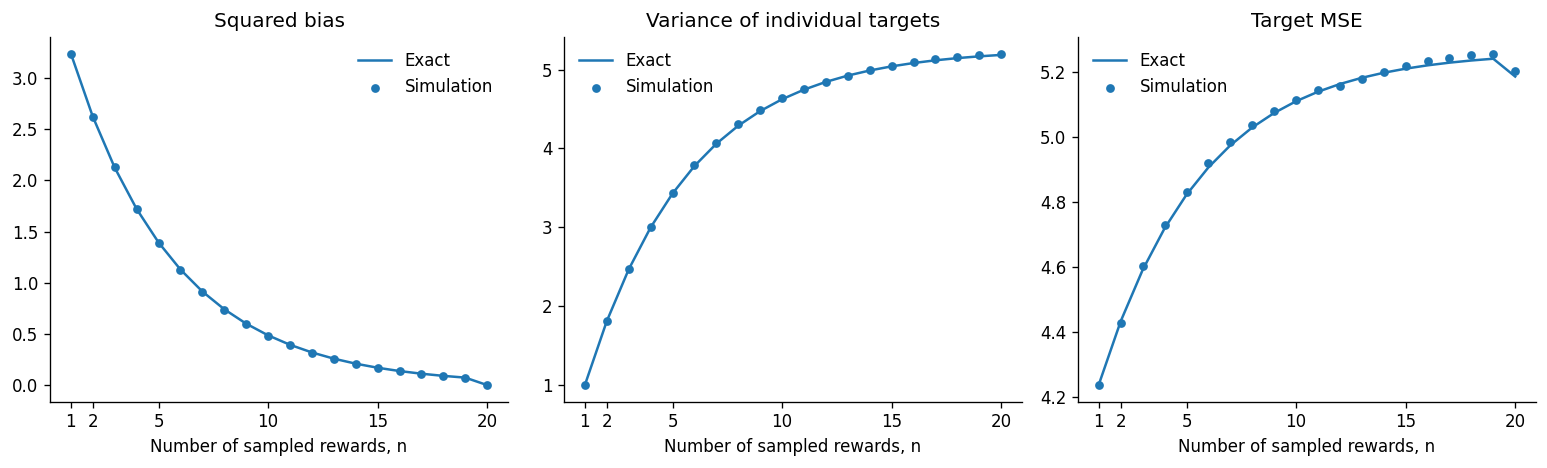

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
backup_lengths = frozen_targets["n"]
statistics_to_plot = ("bias", "variance", "mse")
panel_titles = ("Squared bias", "Variance of individual targets", "Target MSE")

for ax, statistic, title in zip(axes, statistics_to_plot, panel_titles):
    if statistic == "bias":
        exact = frozen_targets["theoretical_bias"] ** 2
        measured = frozen_targets["bias"] ** 2
    else:
        exact = frozen_targets["theoretical_" + statistic]
        measured = frozen_targets[statistic]

    ax.plot(backup_lengths, exact, label="Exact")
    ax.scatter(backup_lengths, measured, s=18, label="Simulation")
    ax.set_title(title)
    ax.set_xlabel("Number of sampled rewards, n")
    ax.set_xticks([1, 2, 5, 10, 15, 20])
    ax.legend(frameon=False)

fig.tight_layout()
plt.show()

Longer targets have less bootstrap bias and more reward-noise variance.

For this two-unit bootstrap error, the one-step target has the lowest MSE. A tradeoff does not require the optimum to be an intermediate backup length. A larger bootstrap error would change the MSE comparison while leaving reward-noise variance unchanged.

This example is deliberately simple. It isolates target bias and variance, but it doesn't tell us how the trained methods behave when state sequences vary and the bootstrap estimates improve. We'll examine that next.

## The Main Experiment: Two States and a Fixed Policy

Our main environment has two physical states, A and B, and two actions: stay and switch. Stay leaves the physical state unchanged; switch moves to the other state. The policy chooses stay with probability 0.8 and switch with probability 0.2 in either state.

The reward depends on the state just left. Leaving A gives $-2$ or 0 with equal probability. Leaving B gives 0 or $+2$ with equal probability. The same distribution applies whether we stay or switch.

![The arrows show the fixed policy probabilities and the rewards for each source state.](two_state_environment.png)

The arrows show the fixed policy probabilities and the rewards for each source state.

The 0.8 and 0.2 labels describe the policy's choice of action. Once an action is chosen, the next physical state is deterministic. The reward draw is independent of the action and earlier reward noise.

We still use exactly 20 steps per episode and $\gamma=0.9$. Every episode starts in A. Neither physical state is absorbing; our prediction objective ends at the horizon. The learner therefore uses $V(h,s)$, where $h$ is steps remaining and $s$ is A or B, with $V(0,s)=0$.

The environment diagrams show the physical states and rewards. We keep the horizon in the definition of the prediction task rather than adding another transition diagram.

### Calculating the True Values

Under the fixed policy, the transition matrix and expected rewards are:

$$P=\begin{bmatrix}0.8&0.2\\0.2&0.8\end{bmatrix},\qquad
r=\begin{bmatrix}-1\\+1\end{bmatrix}.$$

The exact finite-horizon values satisfy:

$$v_h=r+\gamma Pv_{h-1},\qquad v_0=0.$$

We use this model to calculate ground truth for evaluating the experiment. The learners themselves receive only sampled episodes. The function also calculates return variance, including the effect of different state sequences.

In [10]:
def two_state_exact_moments(horizon, gamma):
    transition_probabilities = np.array([
        [0.8, 0.2],
        [0.2, 0.8],
    ])
    expected_rewards = np.array([-1.0, 1.0])

    values = np.zeros((horizon + 1, 2))
    return_variances = np.zeros_like(values)

    for steps_remaining in range(1, horizon + 1):
        next_values = values[steps_remaining - 1]
        expected_next_value = transition_probabilities @ next_values
        values[steps_remaining] = expected_rewards + gamma * expected_next_value

        # Immediate reward noise has variance 1 and is independent of the move.
        next_variances = return_variances[steps_remaining - 1]
        next_second_moments = next_variances + next_values**2
        expected_second_moment = transition_probabilities @ next_second_moments
        future_variance = expected_second_moment - expected_next_value**2
        return_variances[steps_remaining] = 1.0 + gamma**2 * future_variance

    return values, return_variances

In [11]:
true_values, true_return_variances = two_state_exact_moments(
    config.horizon, config.gamma
)
starting_value = true_values[config.horizon, 0]

print(f"True 20-step value from A: {starting_value:.6f}")
print(f"True 20-step value from B: {true_values[-1, 1]:.6f}")
print(f"Variance of a full return from A: {true_return_variances[-1, 0]:.6f}")

True 20-step value from A: -2.173903
True 20-step value from B: 2.173903
Variance of a full return from A: 17.690713


The true starting value is approximately $-2.174$. Although the initial reward has mean $-1$, the agent may switch to B and receive positive expected rewards later.

Unlike the one-state example, the rewards are not independent overall. The physical state affects future reward means. The return variance therefore includes covariance terms; it is not just a sum of the individual reward variances.

### Training TD(0) and Monte Carlo

We'll train both methods for 1,000 episodes and repeat the entire process 500 times. Each run starts with zero estimates. Within a run, both methods receive identical states, actions, and rewards.

TD updates after each transition. MC waits until the episode ends and calculates the complete remaining returns. Since the clock decreases at every step, each prediction state $(h,s)$ can appear at most once in an episode. Both methods therefore make the same number of value updates from the same episode data.

The independent runs are stored in separate rows. This keeps the simulation fast without hiding the target calculation or the value update.

In [12]:
def train_two_state(runs, episodes, horizon, gamma, alpha, seed, checkpoints):
    rng = np.random.default_rng(seed)
    run_indices = np.arange(runs)

    # Values are indexed by run, steps remaining, and physical state.
    V_td = np.zeros((runs, horizon + 1, 2))
    V_mc = np.zeros_like(V_td)
    td_history = []
    mc_history = []

    for episode in range(1, episodes + 1):
        current_states = np.zeros(runs, dtype=int)  # Start in A.
        episode_states = np.empty((horizon, runs), dtype=int)
        episode_rewards = np.empty((horizon, runs))

        for step in range(horizon):
            steps_remaining = horizon - step
            episode_states[step] = current_states

            # A has mean reward -1; B has mean reward +1.
            reward_means = 2 * current_states - 1
            reward_noise = 2 * rng.integers(2, size=runs) - 1
            rewards = reward_means + reward_noise

            switch_states = rng.random(runs) < 0.2
            next_states = np.where(switch_states, 1 - current_states, current_states)
            episode_rewards[step] = rewards

            next_values = V_td[run_indices, steps_remaining - 1, next_states]
            targets = rewards + gamma * next_values
            current_values = V_td[run_indices, steps_remaining, current_states]
            td_errors = targets - current_values
            V_td[run_indices, steps_remaining, current_states] += alpha * td_errors

            current_states = next_states

        # Work backward to calculate each complete remaining return for MC.
        returns = np.zeros(runs)

        for step in range(horizon - 1, -1, -1):
            steps_remaining = horizon - step
            states = episode_states[step]
            returns = episode_rewards[step] + gamma * returns

            current_values = V_mc[run_indices, steps_remaining, states]
            mc_errors = returns - current_values
            V_mc[run_indices, steps_remaining, states] += alpha * mc_errors

        if episode in checkpoints:
            td_history.append(V_td.copy())
            mc_history.append(V_mc.copy())

    return {
        "TD(0)": np.asarray(td_history),
        "MC": np.asarray(mc_history),
    }

In [13]:
learning_history = train_two_state(
    runs=config.runs,
    episodes=config.episodes,
    horizon=config.horizon,
    gamma=config.gamma,
    alpha=config.alpha,
    seed=config.seed,
    checkpoints=set(checkpoints),
)

starting_estimates = {}
final_estimates = {}

for method, history in learning_history.items():
    starting_estimates[method] = history[:, :, config.horizon, 0]
    final_estimates[method] = history[-1, :, config.horizon, 0]

learning_statistics = comparison_table(final_estimates, starting_value)
display(learning_statistics.round(6))

,mean,bias,bias_squared,variance,mse
Method,,,,,
TD(0),-2.174080,-0.000176,0.000000,0.174972,0.174972
MC,-2.171911,0.001993,0.000004,0.434774,0.434778


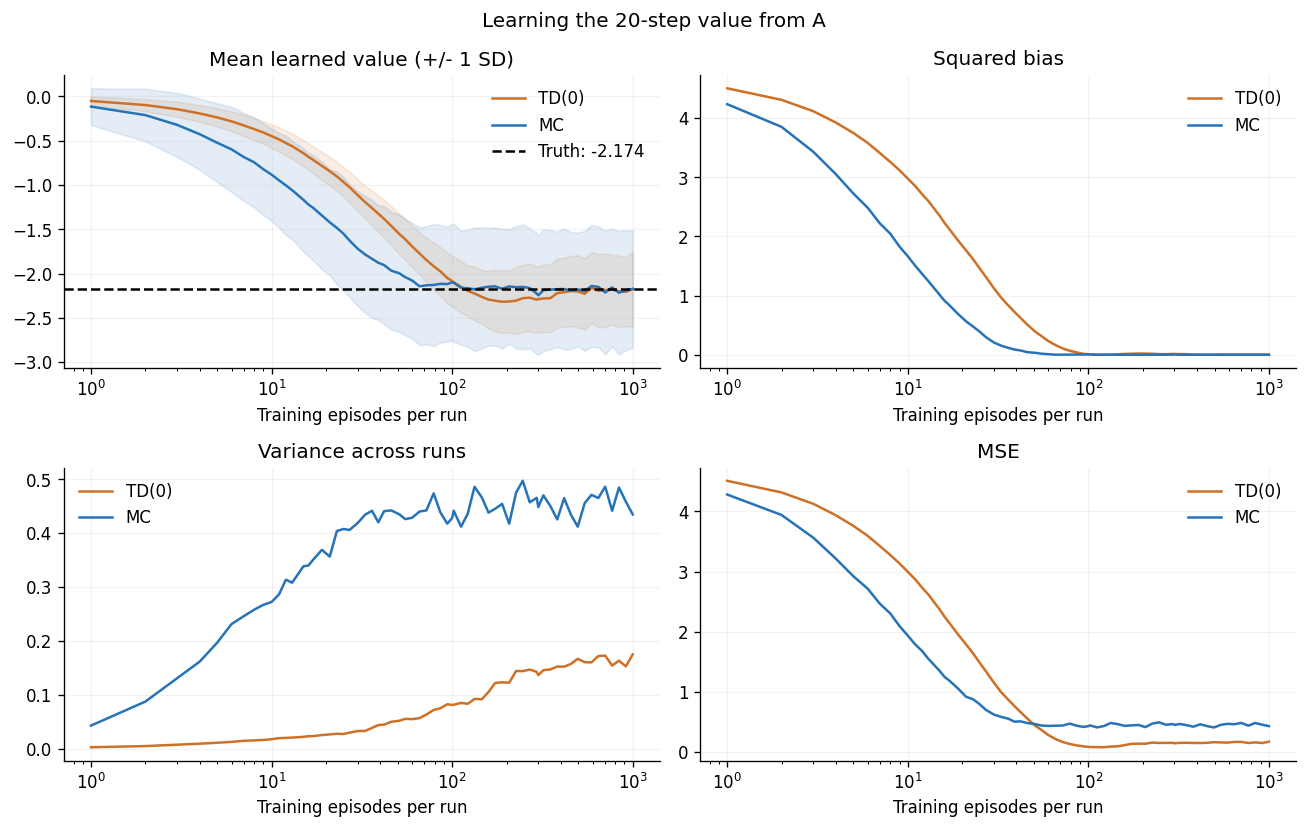

In [14]:
plot_learning_curves(
    starting_estimates,
    checkpoints,
    starting_value,
    "Learning the 20-step value from A",
)

Bias, variance, and MSE of learned starting values across independent training runs.

These curves measure learned estimates, rather than individual update targets. At each checkpoint, we collect the 500 values for starting in A with the full horizon remaining. Their average determines the measured bias; their spread determines the variance.

MC moves away from its zero initialization faster at the beginning, but its estimates have a wider spread. TD's narrower distribution gives it lower MSE later in this experiment. Both means are close to the true value by the end of training. The bias need not fall smoothly at every checkpoint.

The histograms make that distinction easier to inspect. The dashed line marks the true value, and the red line marks the mean learned estimate. The gap shows bias; the spread shows variance.

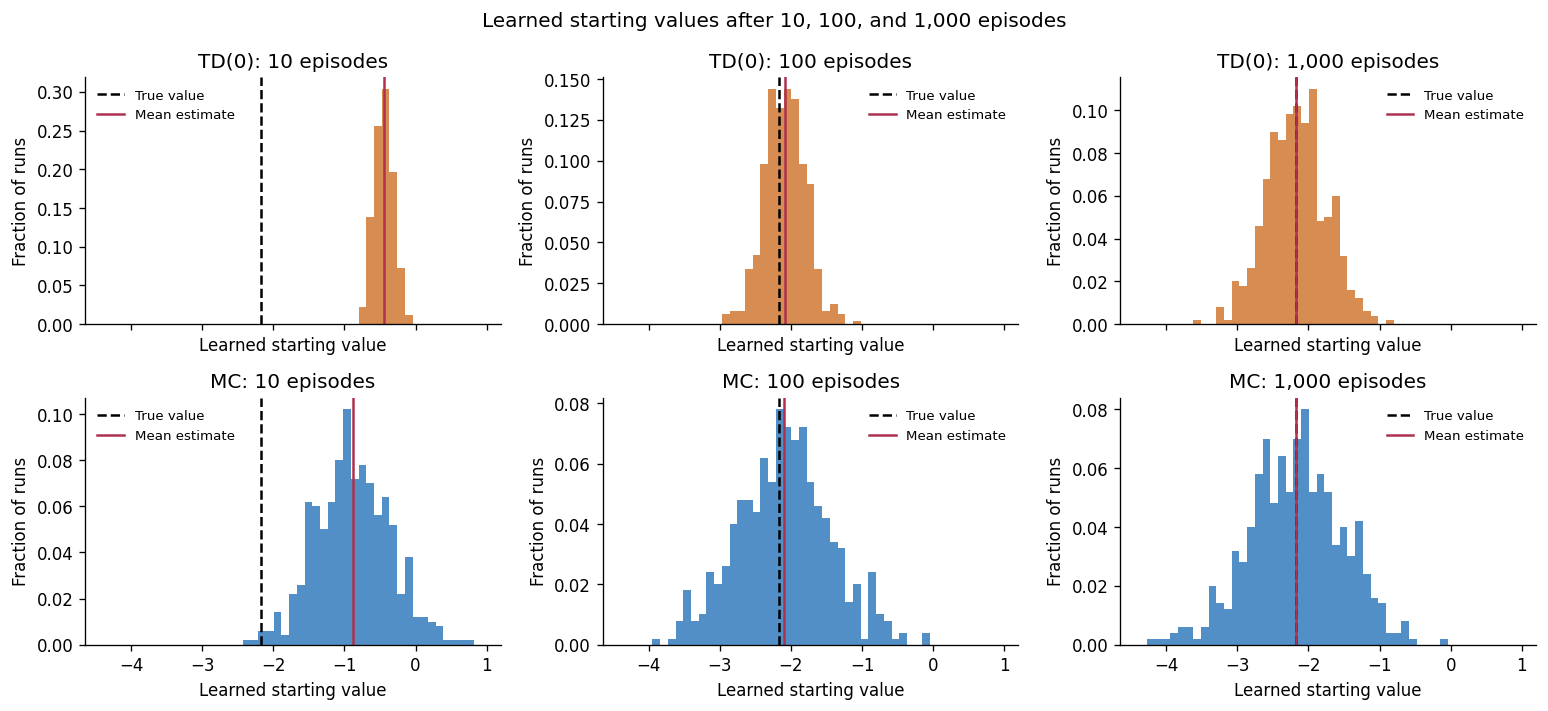

In [15]:
plot_learned_distributions(
    starting_estimates,
    checkpoints,
    starting_value,
    "Learned starting values after 10, 100, and 1,000 episodes",
)

Each histogram contains estimates from 500 separate training runs.

An unbiased MC target does not imply an unbiased estimate after finite training. At the starting state, constant-$\alpha$ MC retains initialization bias:

$$\mathbb{E}[\hat V_K]-v=(1-\alpha)^K(\hat V_0-v).$$

The update rule also determines how much reward noise remains in the estimate. Our constant learning rate keeps admitting new noise, so the across-run variance does not vanish as it would for a sample average of independent complete returns.

## Extending the Main Experiment to n-Step TD

So far, we've compared one sampled reward plus a bootstrap estimate with a complete sampled return. Now we'll compare every backup length from 1 through 20 in the same two-state environment.

The n-step target is:

$$Y_t^{(n)}=\sum_{k=0}^{n-1}\gamma^kR_{t+k+1}
+\gamma^n\hat V(h-n,S_{t+n}).$$

If fewer than $n$ steps remain, we use the complete remaining return and no bootstrap term. The endpoints are TD(0) at $n=1$ and full MC at $n=20$.

### Training All Backup Lengths

Each method gets the same episode within a run. We collect an episode first, then apply each method's updates in decreasing order of steps remaining. This matches the online dependencies in this finite-horizon task: a bootstrap state with fewer steps remaining has not yet been updated during that episode. The equivalence relies on the clock and fixed policy; it should not be assumed for a general environment that revisits the same prediction state.

The sampled part of the target is extended by one discounted reward as we increase $n$. Each backup length has its own value table.

In [16]:
def train_two_state_n_step(
    num_runs,
    num_episodes,
    horizon,
    gamma,
    alpha,
    seed,
    checkpoints,
):
    rng = np.random.default_rng(seed)
    run_indices = np.arange(num_runs)
    backup_lengths = np.arange(1, horizon + 1)
    num_methods = len(backup_lengths)

    # Separate value tables for each backup length and each training run.
    # The final two dimensions are steps remaining and physical state.
    values = np.zeros((num_methods, num_runs, horizon + 1, 2))
    starting_value_history = []
    checkpoints = set(checkpoints)

    for episode in range(1, num_episodes + 1):
        current_states = np.zeros(num_runs, dtype=int)
        states_by_horizon = np.zeros((num_runs, horizon + 1), dtype=int)
        rewards_by_horizon = np.zeros((num_runs, horizon + 1))

        # Generate one shared episode per run under the fixed policy.
        for step in range(horizon):
            steps_remaining = horizon - step
            states_by_horizon[:, steps_remaining] = current_states

            reward_means = 2 * current_states - 1
            reward_noise = 2 * rng.integers(2, size=num_runs) - 1
            rewards = reward_means + reward_noise
            rewards_by_horizon[:, steps_remaining] = rewards

            switch_states = rng.random(num_runs) < 0.2
            next_states = np.where(
                switch_states, 1 - current_states, current_states
            )
            states_by_horizon[:, steps_remaining - 1] = next_states
            current_states = next_states

        sampled_returns = np.zeros((num_runs, horizon + 1))

        for method_index, n in enumerate(backup_lengths):
            # Increasing n adds one more discounted reward to each prefix.
            for steps_remaining in range(n, horizon + 1):
                reward_horizon = steps_remaining - n + 1
                rewards = rewards_by_horizon[:, reward_horizon]
                sampled_returns[:, steps_remaining] += gamma ** (n - 1) * rewards

            # A later prediction state has not yet been updated this episode.
            # These dependencies match online n-step TD for this clock.
            for steps_remaining in range(horizon, 0, -1):
                states = states_by_horizon[:, steps_remaining]
                targets = sampled_returns[:, steps_remaining].copy()

                if steps_remaining > n:
                    bootstrap_horizon = steps_remaining - n
                    bootstrap_states = states_by_horizon[:, bootstrap_horizon]
                    bootstrap_values = values[
                        method_index,
                        run_indices,
                        bootstrap_horizon,
                        bootstrap_states,
                    ]
                    targets += gamma**n * bootstrap_values

                current_values = values[
                    method_index, run_indices, steps_remaining, states
                ]
                td_errors = targets - current_values
                values[
                    method_index, run_indices, steps_remaining, states
                ] += alpha * td_errors

        if episode in checkpoints:
            starting_values = values[:, :, horizon, 0]
            starting_value_history.append(starting_values.copy())

    return {
        "backup_lengths": backup_lengths,
        "history": np.asarray(starting_value_history),
        "final_values": values,
    }

In [17]:
n_step_history = train_two_state_n_step(
    num_runs=config.runs,
    num_episodes=config.episodes,
    horizon=config.horizon,
    gamma=config.gamma,
    alpha=config.alpha,
    seed=config.seed,
    checkpoints=checkpoints,
)

backup_lengths = n_step_history["backup_lengths"]
history = n_step_history["history"]
n_step_statistics = prediction_statistics(history, starting_value, axis=2)

# The endpoint methods must reproduce the earlier TD and MC experiment.
np.testing.assert_allclose(history[:, 0], starting_estimates["TD(0)"], atol=1e-12)
np.testing.assert_allclose(history[:, -1], starting_estimates["MC"], atol=1e-12)

budget_rows = []

for budget in (10, 30, 100, 300, 1000):
    checkpoint_index = np.flatnonzero(checkpoints == budget)[0]
    measured_mse = n_step_statistics["mse"][checkpoint_index]
    best_index = int(np.argmin(measured_mse))

    row = {
        "episodes": budget,
        "TD(0) MSE": measured_mse[0],
        "lowest measured MSE at n": backup_lengths[best_index],
        "lowest measured MSE": measured_mse[best_index],
        "MC MSE": measured_mse[-1],
    }
    budget_rows.append(row)

budget_table = pd.DataFrame(budget_rows).set_index("episodes")
display(budget_table.round(6))

,TD(0) MSE,lowest measured MSE at n,lowest measured MSE,MC MSE
episodes,,,,
10,2.997840,6,1.874396,1.938897
30,1.156334,4,0.458023,0.625769
100,0.089465,1,0.089465,0.434019
300,0.149459,1,0.149459,0.453576
1000,0.174972,1,0.174972,0.434778


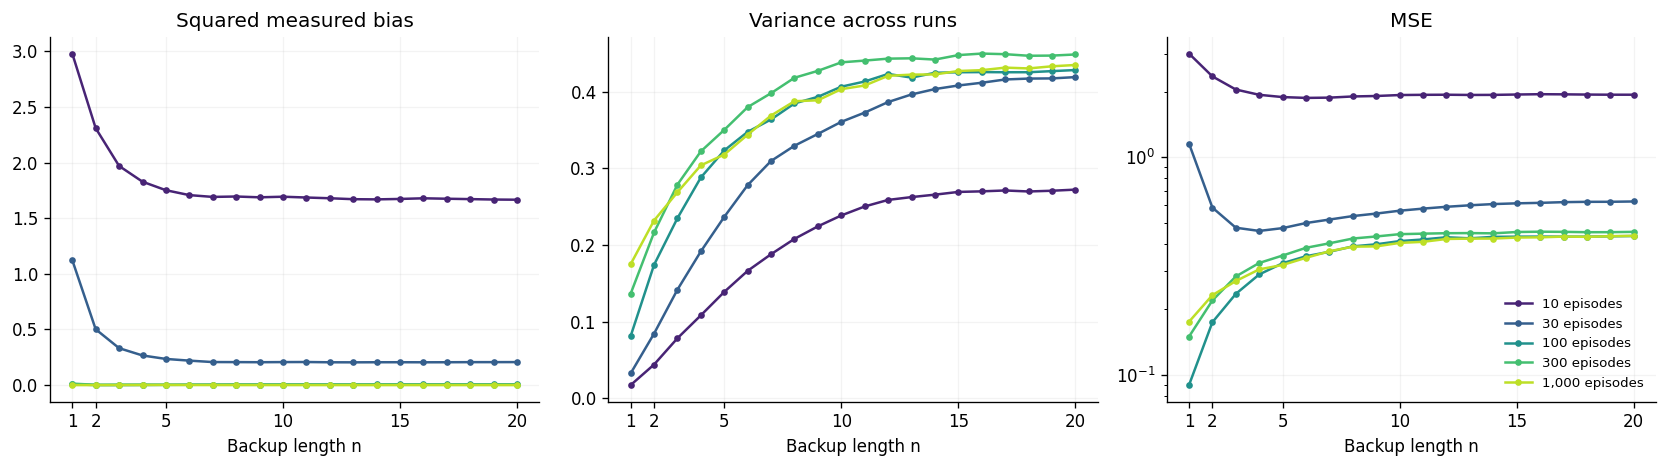

In [18]:
training_budgets = (10, 30, 100, 300, 1000)
colors = plt.cm.viridis(np.linspace(0.1, 0.9, len(training_budgets)))
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for budget, color in zip(training_budgets, colors):
    checkpoint_index = np.flatnonzero(checkpoints == budget)[0]

    for ax, statistic in zip(axes, ("bias_squared", "variance", "mse")):
        values = n_step_statistics[statistic][checkpoint_index]
        ax.plot(
            backup_lengths,
            values,
            marker="o",
            markersize=3,
            color=color,
            label=f"{budget:,} episodes",
        )

for ax, title in zip(axes, ("Squared measured bias", "Variance across runs", "MSE")):
    ax.set_title(title)
    ax.set_xlabel("Backup length n")
    ax.set_xticks([1, 2, 5, 10, 15, 20])
    ax.grid(alpha=0.15)

axes[-1].set_yscale("log")
axes[-1].legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

Measured error components at fixed training budgets in the two-state environment.

Intermediate backups have lower measured MSE early in this run. At 30 episodes, a four-step backup gives a better balance than either one-step TD or full MC. Later, one-step TD has learned useful bootstrap values and has the lowest measured MSE.

The exact winning backup length is an empirical result from these 500 runs. Nearby values can have similar errors, and we select and evaluate the minimum on the same runs. The table is a description of this experiment, rather than a guarantee that the selected n will win on new runs or in another environment. Unlike the controlled target calculation, these learned-value statistics are not exact analytical moments.

We can also follow a few backup lengths throughout training. The dotted line in the mean-value panel marks the true starting value; the other panels measure errors across runs.

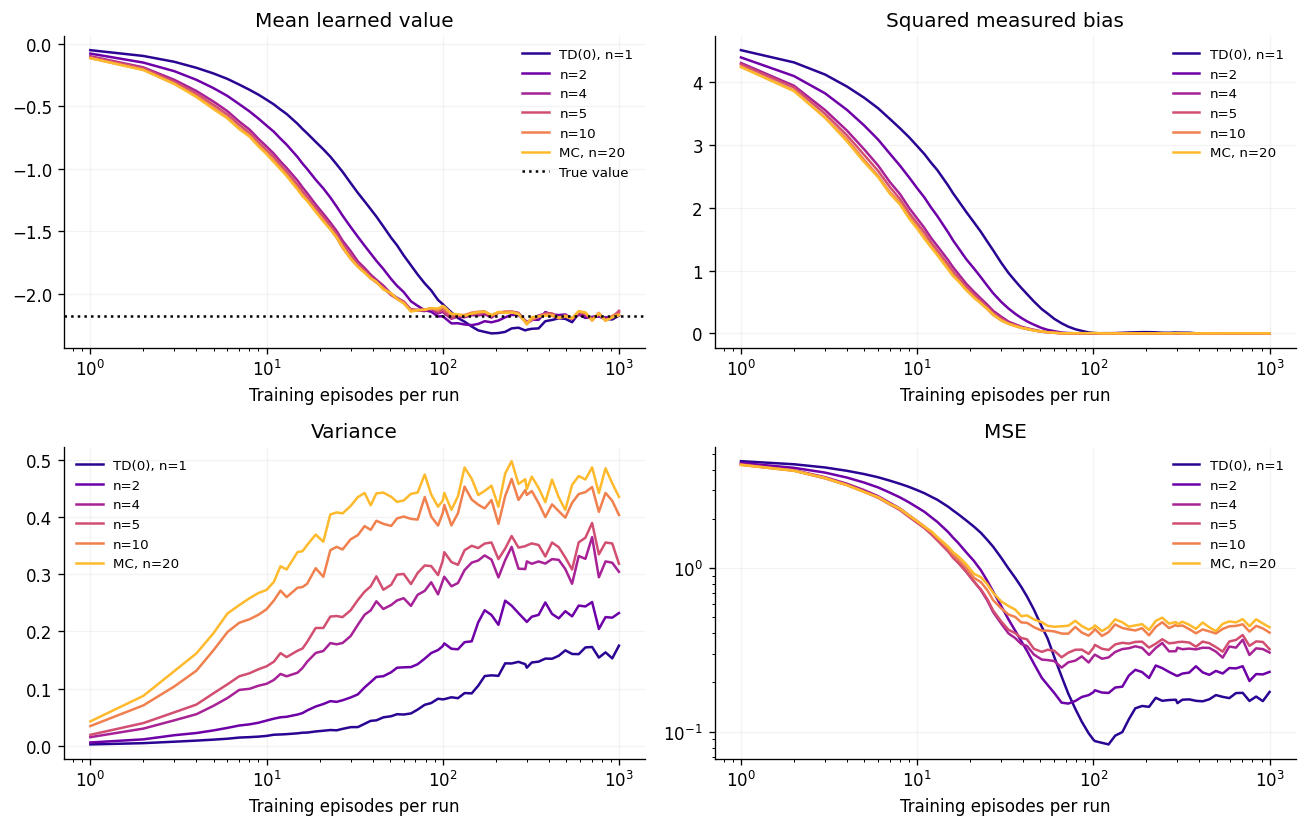

In [19]:
selected_lengths = (1, 2, 4, 5, 10, 20)
colors = plt.cm.plasma(np.linspace(0.05, 0.85, len(selected_lengths)))
fig, axes = plt.subplots(2, 2, figsize=(11, 7))

for n, color in zip(selected_lengths, colors):
    index = n - 1
    label = f"n={n}"
    if n == 1:
        label = "TD(0), n=1"
    elif n == config.horizon:
        label = "MC, n=20"

    for ax, statistic in zip(axes.flat, ("mean", "bias_squared", "variance", "mse")):
        ax.plot(
            checkpoints,
            n_step_statistics[statistic][:, index],
            color=color,
            label=label,
        )

axes[0, 0].axhline(
    starting_value, color="black", linestyle=":", label="True value"
)

for ax, title in zip(axes.flat, ("Mean learned value", "Squared measured bias", "Variance", "MSE")):
    ax.set_title(title)
    ax.set_xlabel("Training episodes per run")
    ax.set_xscale("log")
    ax.grid(alpha=0.15)
    ax.legend(frameon=False, fontsize=8)

axes[1, 1].set_yscale("log")
fig.tight_layout()
plt.show()

The same two-state task, viewed across training time rather than backup length.

## What These Experiments Show

The one-state example isolates the mechanism. Adding independent sampled rewards increases target variance, while an inaccurate bootstrap estimate contributes bias. Longer backups change the balance between these two sources of error.

The two-state environment shows how that balance appears during learning with a nontrivial fixed policy and state-dependent rewards. The bootstrap values change with experience, so the best backup length depends on the training budget as well as the environment and learning rate.

The policy stayed fixed throughout. We evaluated predictions of returns, rather than learning which action to choose. There was no need to improve the policy to compare TD and MC prediction.

The target and learned estimate remain different objects. MC targets are unbiased for these finite-horizon on-policy returns, but finite-training MC estimates can retain initialization bias. A TD target becomes unbiased if its bootstrap values are exact. Neither fact gives a universal ordering of learned-value MSE.

All methods used a constant learning rate of 0.05, and all backup lengths received equal episode data and equal update counts. This is a controlled comparison at one step size, rather than a learning-rate search for each method. The variance plateaus reflect the constant step size; different choices can change the result.

The simpler example explains the source of the tradeoff. The two-state learning experiment shows how that understanding carries over when state sequences also affect the returns.

## References

1. Sutton, R. S., & Barto, A. G. (2018). *Reinforcement Learning: An Introduction*, second edition. MIT Press. Chapters 5–7 cover Monte Carlo prediction, temporal-difference learning, and n-step bootstrapping. [Book website](https://incompleteideas.net/book/the-book-2nd.html).
2. Sutton, R. S., & Barto, A. G. *Chapter 6: Temporal Difference Learning*. [Author lecture slides](https://people.cs.umass.edu/~barto/courses/cs687/Chapter%206.pdf).

The environments and controlled calculations in this notebook are constructed examples, rather than reproductions of a numbered textbook figure.

<script src="https://utteranc.es/client.js"
        repo="novastar53/novastar53.github.io"
        issue-term="pathname"
        theme="github-light"
        crossorigin="anonymous"
        async>
</script>